# U.S. Macroeconomic Data Pipeline & Dashboard
## Northwestern University · Topics in Data Engineering · Fall 2026

**Research question:** How have unemployment, consumer prices, and the federal funds rate evolved since 2000, and how stable are their descriptive relationships?

This notebook reads the **validated SQLite database**, performs reproducible exploratory analysis, and exports figures and findings. It does not call an API or contain credentials. Run `macro-pipeline update` first, then execute this notebook from top to bottom. All values and conclusions below are calculated from the database snapshot.

The deliverable covers API ingestion, database storage, an executable end-to-end Airflow DAG, a reproducible GitHub repository, and EDA. The interactive Streamlit dashboard is a separate application. The requested PowerPoint is outside the current scope.


### 1. Sources, units, and design choices

| Series | Meaning | Units | Adjustment |
|---|---|---|---|
| [UNRATE](https://fred.stlouisfed.org/series/UNRATE) | Civilian unemployment rate (BLS) | Percent | Seasonally adjusted |
| [CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) | All-items urban consumer price index (BLS) | 1982–84 = 100 | Seasonally adjusted |
| [FEDFUNDS](https://fred.stlouisfed.org/series/FEDFUNDS) | Effective federal funds rate (Federal Reserve) | Percent, monthly average of daily figures | Not seasonally adjusted |

The published analysis begins in January 2000. Raw ingestion also retrieves 1999 to provide a twelve-month warm-up for inflation. API requests specify the same FRED real-time/vintage date for all three series. A full-history daily refresh captures revisions. Raw JSON, checksums, metadata, run statuses, and stage durations are retained locally.

**Missing data policy:** preserve explicit FRED `.` as null; distinguish it from unreleased trailing months. Reject omitted calendar months, implausible values, stale series, and source-missing shares above 5%. Never forward-fill or interpolate observations. Percentage changes explicitly disable implicit filling. Each statistic excludes only the nulls relevant to that calculation.


In [1]:
from pathlib import Path
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from macro_pipeline.config import Settings
from macro_pipeline.db import read_dataset, connect, VALUE_COLUMNS
from macro_pipeline.transform import validate_monthly
from macro_pipeline.analysis import LABELS, ECONOMIC_COLUMNS, findings, lag_correlations, write_analysis

settings = Settings.from_env()
root = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
df, run = read_dataset(settings.db_path)
validation = validate_monthly(df.reset_index(), run['as_of'])
display(Markdown(f"**FRED vintage:** {run['as_of']} · **Rows:** {len(df)} · **Published:** {run['published_at']}"))
display(df.tail(8))

**FRED vintage:** 2026-11-08 · **Rows:** 322 · **Published:** 2026-11-09T02:00:31.707481+00:00

,unrate,cpiaucsl,fedfunds,cpi_yoy,cpi_mom,unrate_change_pp,fedfunds_change_pp,real_rate_proxy,unrate_status,cpiaucsl_status,fedfunds_status
date,,,,,,,,,,,
2026-03-01,4.3,330.293,3.64,3.285958,0.865144,-0.1,0.00,0.354042,observed,observed,observed
2026-04-01,4.3,332.407,3.64,3.779246,0.640038,0.0,0.00,-0.139246,observed,observed,observed
2026-05-01,4.3,333.979,3.63,4.166615,0.472914,0.0,-0.01,-0.536615,observed,observed,observed
2026-06-01,4.2,332.568,3.63,3.463531,-0.422482,-0.1,0.00,0.166469,observed,observed,observed
2026-07-01,4.1,332.813,3.63,3.303856,0.073669,-0.1,0.00,0.326144,observed,observed,observed
2026-08-01,4.1,334.131,3.63,3.353016,0.396018,0.0,0.00,0.276984,observed,observed,observed
2026-09-01,4.2,336.298,3.75,3.717251,0.648548,0.1,0.12,0.032749,observed,observed,observed
2026-10-01,4.1,NaN,3.88,NaN,NaN,-0.1,0.13,NaN,observed,not_released,observed


### 2. Audit the database and data quality

In [2]:
with connect(settings.db_path, readonly=True) as conn:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn)
    stages = pd.read_sql_query('SELECT stage, status, duration_seconds FROM pipeline_steps WHERE run_id=? ORDER BY started_at', conn, params=(run['run_id'],))
    raw_counts = pd.read_sql_query('SELECT series_id, COUNT(*) AS raw_observations FROM raw_observations WHERE run_id=? GROUP BY series_id', conn, params=(run['run_id'],))
display(tables)
display(raw_counts)
display(stages)
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == validation['rows']
assert stages.status.eq('SUCCESS').all()
display(pd.DataFrame(validation['series']).T)

,name
0,dataset_state
1,monthly_indicators
2,pipeline_runs
3,pipeline_steps
4,raw_observations
5,raw_payloads
6,staged_monthly


,series_id,raw_observations
0,CPIAUCSL,333
1,FEDFUNDS,334
2,UNRATE,334


,stage,status,duration_seconds
0,extract_api,SUCCESS,7.441552
1,store_raw,SUCCESS,0.036862
2,clean_transform,SUCCESS,0.035296
3,validate_quality,SUCCESS,0.014086
4,publish_database,SUCCESS,0.010392
5,verify_update,SUCCESS,0.010763


,latest_date,latest_value,missing,source_missing,not_released,age_days
unrate,2026-10-01,4.1,1,1,0,38
cpiaucsl,2026-09-01,336.298,2,1,1,68
fedfunds,2026-10-01,3.88,0,0,0,38


In [3]:
missing = pd.DataFrame({'missing_count': df[VALUE_COLUMNS].isna().sum(), 'missing_pct': df[VALUE_COLUMNS].isna().mean() * 100})
display(missing)
display(df.loc[df[['unrate', 'cpiaucsl', 'fedfunds']].isna().any(axis=1)])
display(Markdown('\n'.join('- ' + w for w in validation['warnings'])))

,missing_count,missing_pct
unrate,1,0.310559
cpiaucsl,2,0.621118
fedfunds,0,0.000000
cpi_yoy,2,0.621118
cpi_mom,3,0.931677
unrate_change_pp,2,0.621118
fedfunds_change_pp,0,0.000000
real_rate_proxy,2,0.621118


,unrate,cpiaucsl,fedfunds,cpi_yoy,cpi_mom,unrate_change_pp,fedfunds_change_pp,real_rate_proxy,unrate_status,cpiaucsl_status,fedfunds_status
date,,,,,,,,,,,
2025-10-01,NaN,NaN,4.09,NaN,NaN,NaN,-0.13,NaN,source_missing,source_missing,observed
2026-10-01,4.1,NaN,3.88,NaN,NaN,-0.1,0.13,NaN,observed,not_released,observed


- unrate: 1 explicit source-missing month(s); retained as null, never imputed.
- cpiaucsl: 1 explicit source-missing month(s); retained as null, never imputed.
- cpiaucsl: 1 trailing unreleased month(s); no imputation.

**An actual data-engineering edge case:** October 2025 unemployment and CPI are absent in the source because the federal government shutdown interrupted data collection. See the [BLS CPS explanation](https://www.bls.gov/cps/methods/2025-federal-government-shutdown-impact-cps.htm) and [BLS CPI explanation](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm). The missing observation is retained. Consequently, month-over-month growth touching the gap and year-over-year growth using it as the denominator are also missing. A missing value does not mean zero inflation or zero unemployment.

The latest CPI month may lag the latest unemployment/rate month because release calendars differ. Latest-value comparisons therefore show each observation's date, while scatter plots and correlations pair matching months.


### 3. Derived variables and descriptive statistics

`CPI YoY = 100 × (CPI[t] / CPI[t−12] − 1)`; `CPI MoM = 100 × (CPI[t] / CPI[t−1] − 1)`. Rate changes are percentage-point differences. The ex-post real-rate proxy is `FEDFUNDS − CPI YoY`; it is not an expected real interest rate.

In [4]:
stats = df[VALUE_COLUMNS].describe(percentiles=[.05, .25, .5, .75, .95]).T
display(stats.round(3))
peaks = pd.DataFrame([{'indicator': LABELS[c], 'minimum': df[c].min(), 'minimum_month': df[c].idxmin().strftime('%Y-%m'), 'maximum': df[c].max(), 'maximum_month': df[c].idxmax().strftime('%Y-%m')} for c in ['unrate', 'cpi_yoy', 'fedfunds']])
display(peaks)

,count,mean,std,min,5%,25%,50%,75%,95%,max
unrate,321.0,5.600,1.930,3.400,3.600,4.200,5.000,6.200,9.500,14.800
cpiaucsl,320.0,235.950,43.757,169.300,177.255,202.600,232.364,257.070,320.318,336.298
fedfunds,322.0,2.059,2.021,0.050,0.080,0.150,1.415,3.880,5.330,6.540
cpi_yoy,320.0,2.604,1.715,-1.959,0.034,1.666,2.406,3.339,5.972,8.979
cpi_mom,319.0,0.216,0.305,-1.771,-0.207,0.064,0.224,0.361,0.641,1.377
unrate_change_pp,320.0,0.000,0.636,-2.200,-0.300,-0.100,0.000,0.100,0.300,10.400
fedfunds_change_pp,322.0,-0.004,0.180,-0.960,-0.300,-0.010,0.000,0.020,0.230,0.700
real_rate_proxy,320.0,-0.556,2.176,-8.372,-4.868,-1.522,-0.646,0.784,2.726,3.844


,indicator,minimum,minimum_month,maximum,maximum_month
0,Unemployment rate (%),3.400000,2023-04,14.800000,2020-04
1,"CPI inflation (YoY, %)",-1.958761,2009-07,8.979361,2022-06
2,Federal funds rate (%),0.050000,2020-04,6.540000,2000-07


### 4. Historical trends

The first figure uses separate axes because a price index and percentage rates have different units. The second compares inflation and the policy rate in percent; their difference is measured in percentage points. Gaps in the charts are intentional.

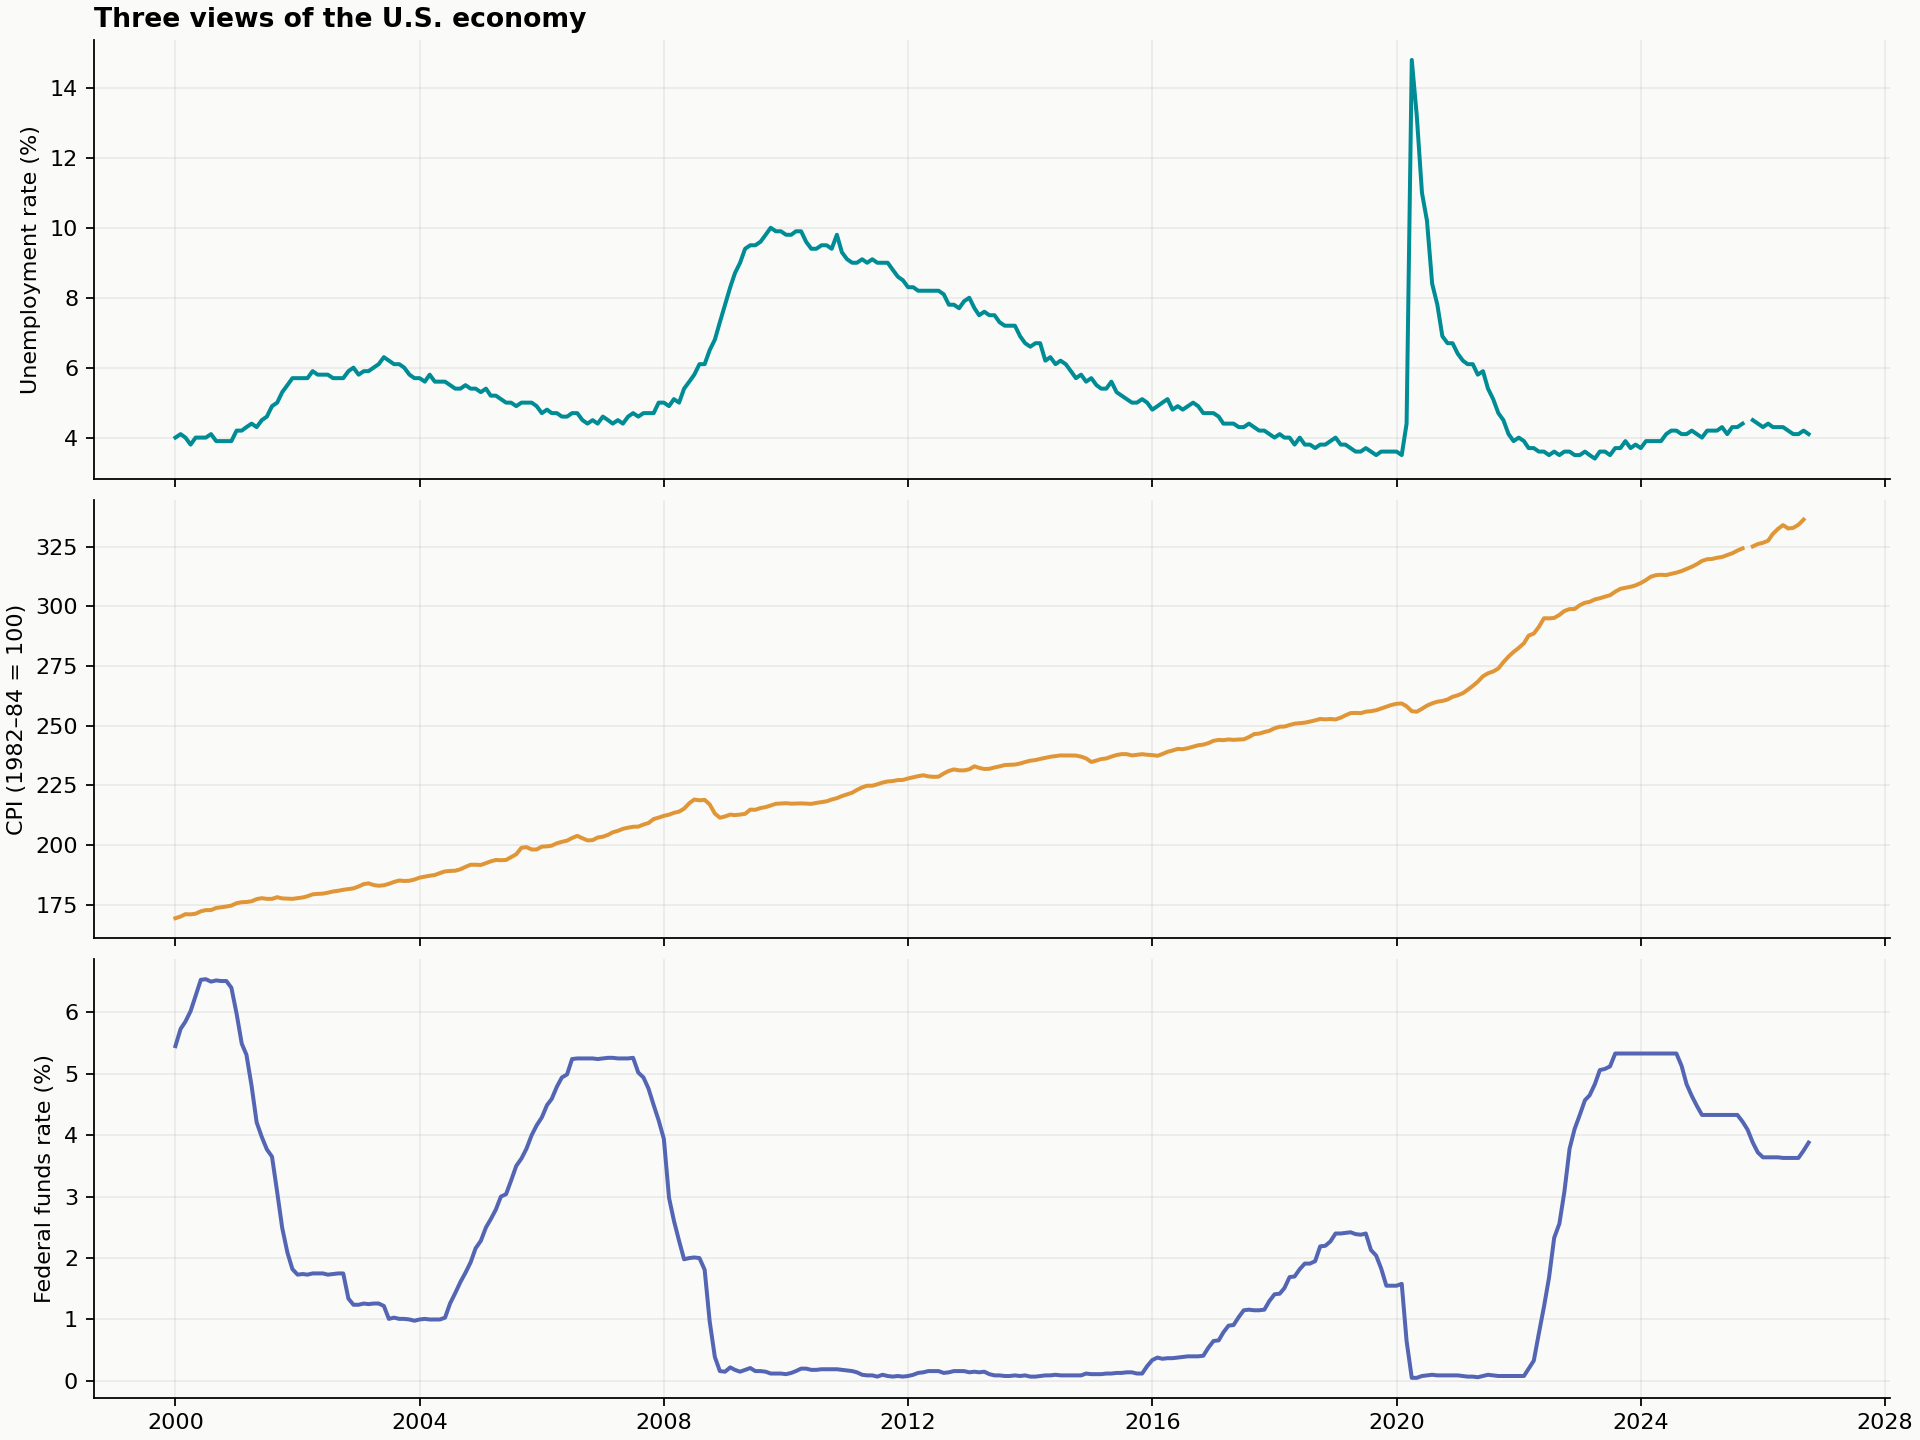

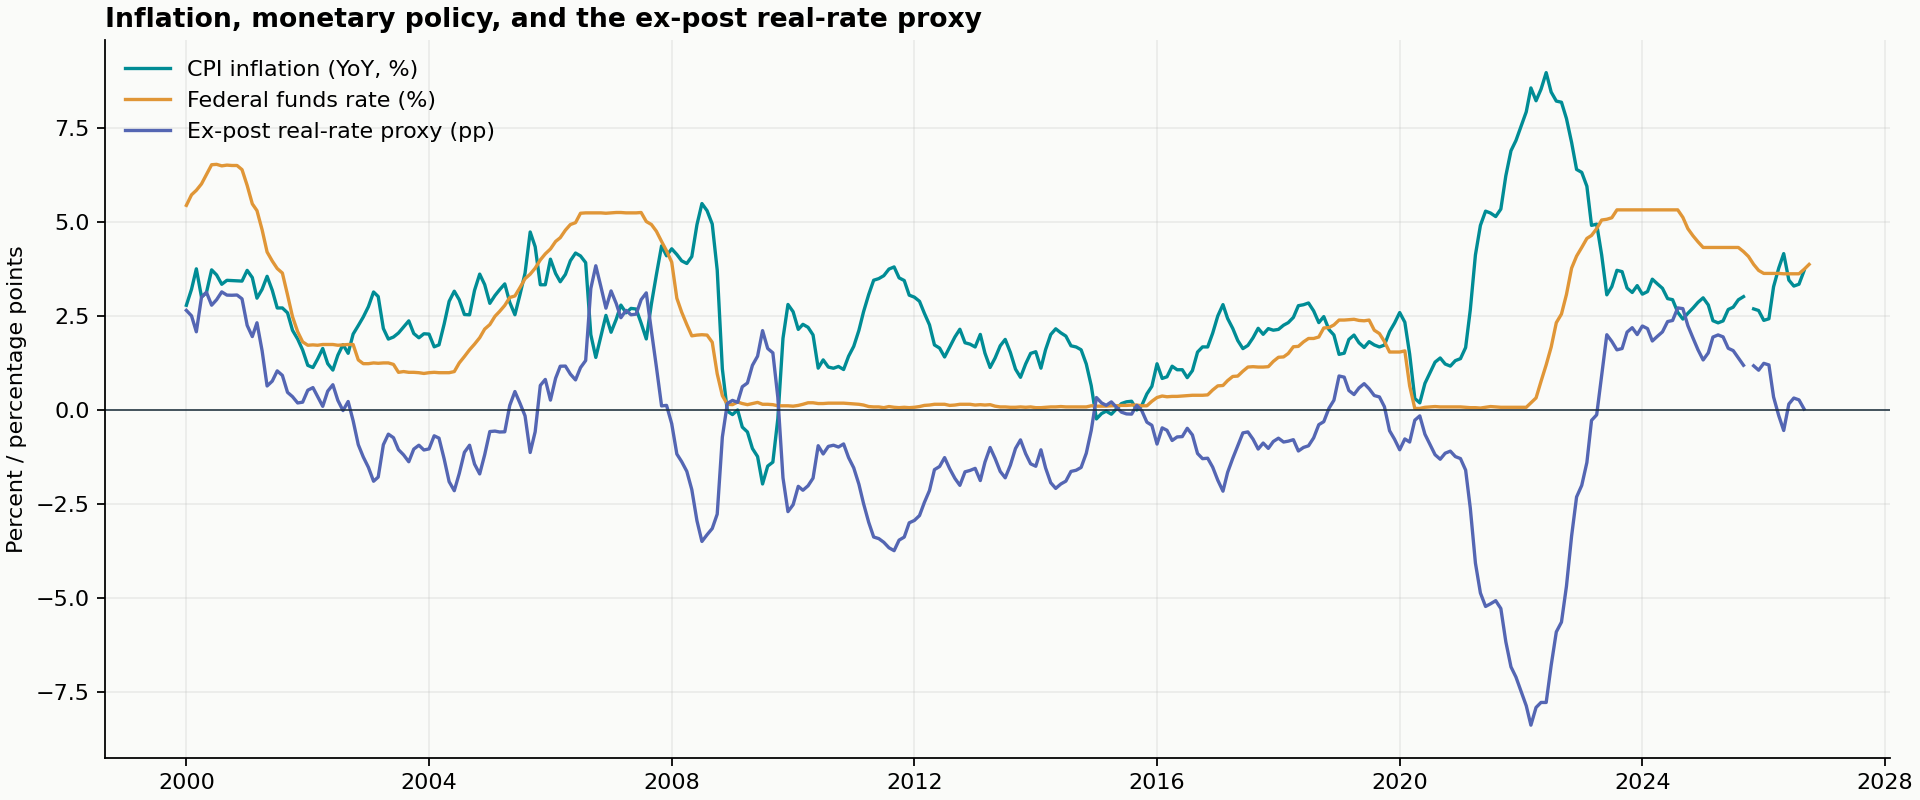

In [5]:
analysis = write_analysis(df, run, root / 'reports')
display(Image(filename=str(root / 'reports/figures/historical_trends.png')))
display(Image(filename=str(root / 'reports/figures/inflation_and_policy.png')))

In [6]:
annual = df[ECONOMIC_COLUMNS].resample('YS').agg(['mean', 'count'])
display(annual.tail(8).round(3))
display(Markdown('Annual averages use available months only; counts disclose missing and partial years. They should not be interpreted as full-year averages when fewer than 12 months are observed.'))

unrate       cpi_yoy       fedfunds      
             mean count    mean count     mean count
date                                                
2019-01-01  3.675    12   1.813    12    2.158    12
2020-01-01  8.100    12   1.255    12    0.376    12
2021-01-01  5.350    12   4.677    12    0.080    12
2022-01-01  3.650    12   7.998    12    1.683    12
2023-01-01  3.625    12   4.146    12    5.024    12
2024-01-01  4.025    12   2.954    12    5.143    12
2025-01-01  4.264    11   2.692    11    4.212    12
2026-01-01  4.230    10   3.322     9    3.671    10

Annual averages use available months only; counts disclose missing and partial years. They should not be interpreted as full-year averages when fewer than 12 months are observed.

### 5. Correlation and transformation sensitivity

A trending price level can produce misleading correlations. We use inflation, unemployment, and the policy rate for the main relationship analysis and compare levels with monthly changes. Counts are reported because pairwise-complete samples can differ.

,unrate,cpi_yoy,fedfunds
unrate,1.000,-0.437,-0.61
cpi_yoy,-0.437,1.000,0.33
fedfunds,-0.610,0.330,1.00


,unrate,cpi_yoy,fedfunds
unrate,1.000,-0.196,-0.236
cpi_yoy,-0.196,1.000,0.140
fedfunds,-0.236,0.140,1.000


,unrate,cpi_yoy,fedfunds
unrate,321,320,321
cpi_yoy,320,320,320
fedfunds,321,320,322


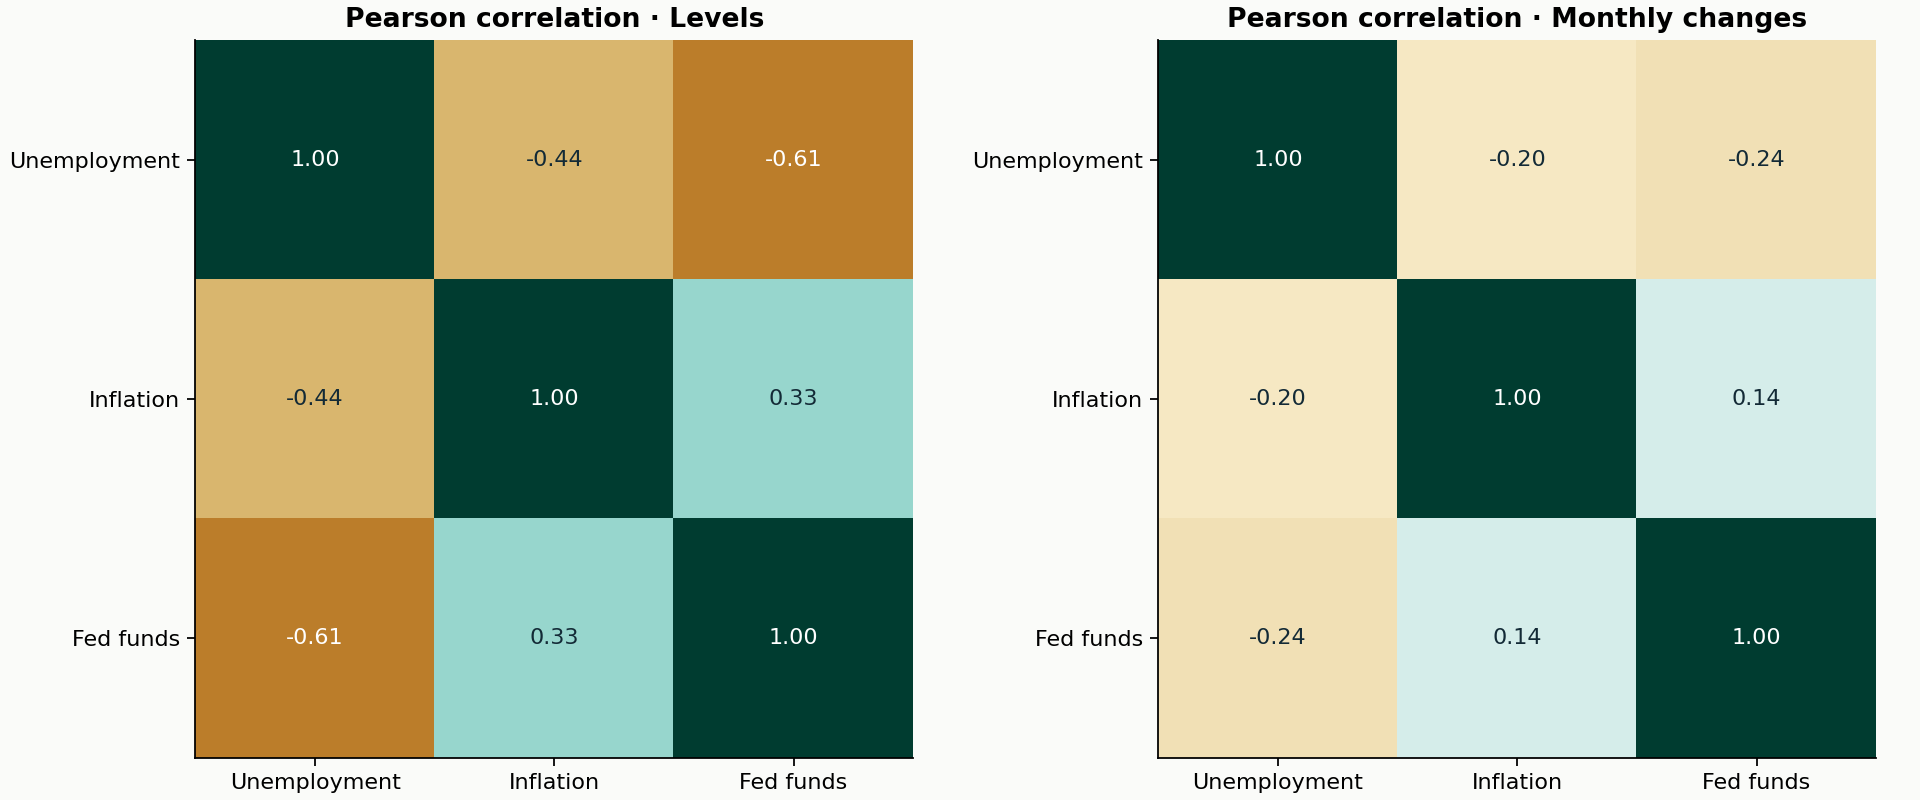

In [7]:
levels = df[ECONOMIC_COLUMNS]
changes = levels.diff()
display(levels.corr().round(3))
display(changes.corr().round(3))
pair_counts = levels.notna().astype(int).T.dot(levels.notna().astype(int))
display(pair_counts)
display(Image(filename=str(root / 'reports/figures/correlations.png')))

### 6. Stability across time

A scatter plot colored by year and a 60-month rolling correlation expose changes that a full-sample coefficient can hide. Rolling windows require all 60 paired observations; official missing months create gaps. The subperiods below are descriptive calendar partitions, not a formal recession classification.

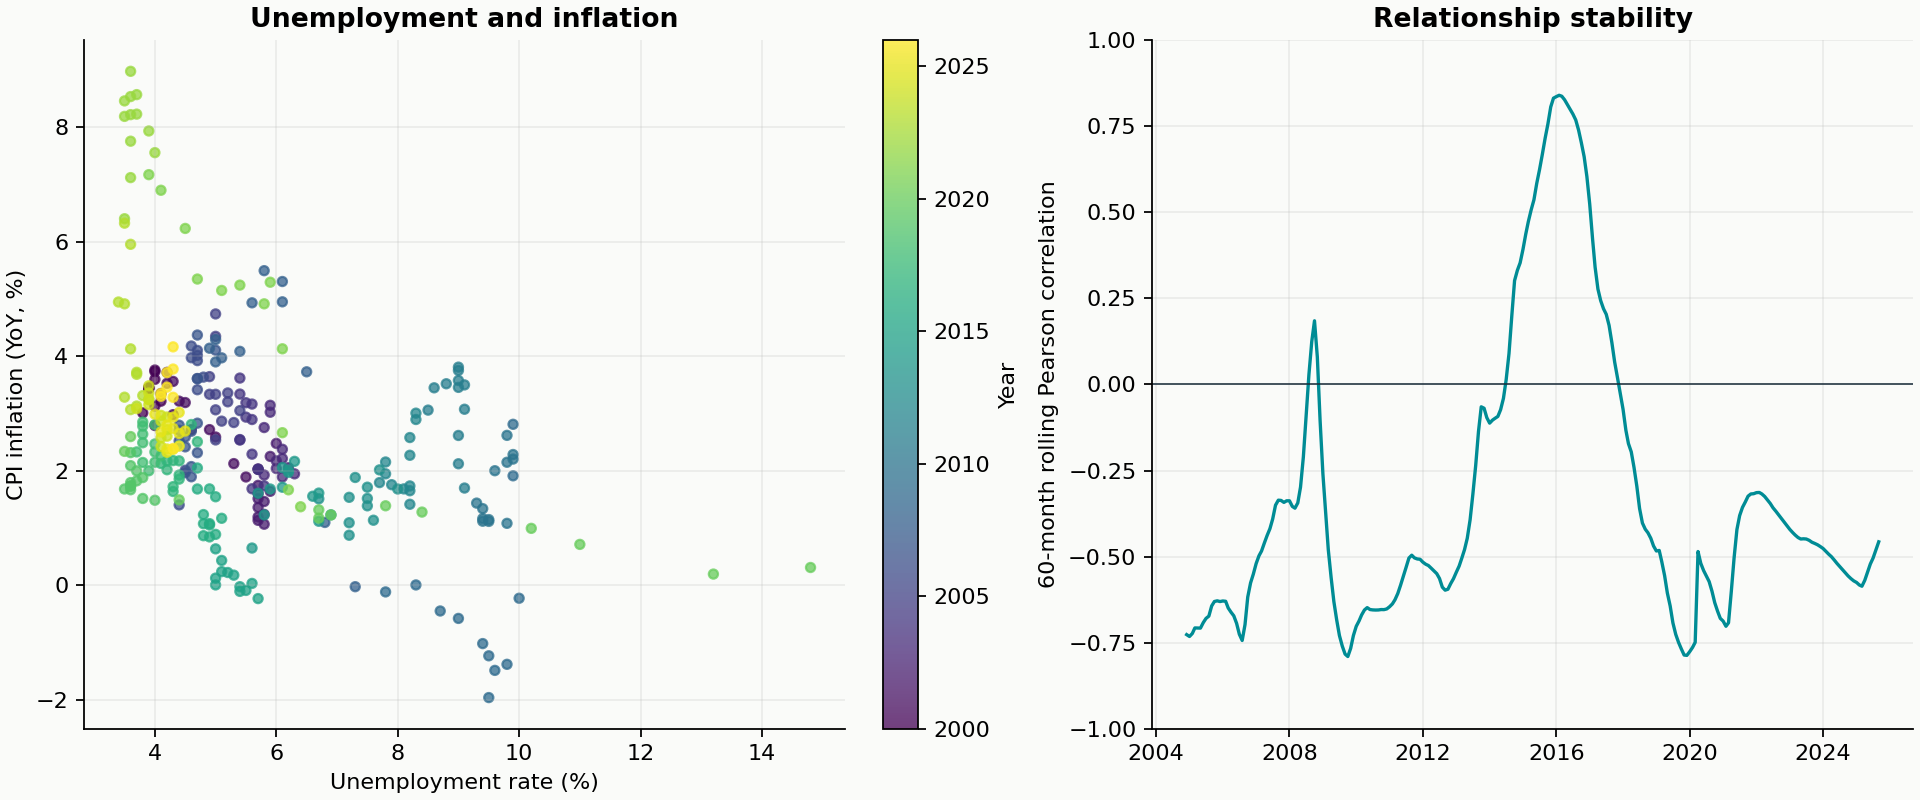

,period,paired_months,unemployment_mean,inflation_mean,fedfunds_mean,unemployment_inflation_r
0,2000–2007,96,5.042,2.777,3.433,-0.547
1,2008–2019,144,6.441,1.769,0.685,-0.134
2,2020 onward,80,4.768,3.898,2.865,-0.508


In [8]:
display(Image(filename=str(root / 'reports/figures/relationship_stability.png')))
periods = [('2000–2007', '2000-01-01', '2007-12-01'), ('2008–2019', '2008-01-01', '2019-12-01'), ('2020 onward', '2020-01-01', df.index.max())]
period_summary = []
for label, start, end in periods:
    part = df.loc[start:end, ECONOMIC_COLUMNS]
    pair = part[['unrate', 'cpi_yoy']].dropna()
    period_summary.append({'period': label, 'paired_months': len(pair), 'unemployment_mean': part.unrate.mean(), 'inflation_mean': part.cpi_yoy.mean(), 'fedfunds_mean': part.fedfunds.mean(), 'unemployment_inflation_r': pair.unrate.corr(pair.cpi_yoy)})
display(pd.DataFrame(period_summary).round(3))

### 7. Exploratory lag relationships

Positive lag k means the federal funds rate at t is paired with the outcome at t+k. Shifts happen on the complete monthly calendar before nulls are dropped, so a missing month cannot shorten a lag. A policy response to the economy creates endogeneity: this is not a causal estimate of monetary policy. Searching 25 lags also introduces multiple-comparison risk.

In [9]:
lag_table = lag_correlations(df)
display(lag_table.pivot(index='lag_months', columns='outcome', values='pearson_r').round(3))
ax = lag_table.pivot(index='lag_months', columns='outcome', values='pearson_r').plot(figsize=(10, 4), color=['#008c95', '#d68b29'])
ax.set(xlabel='Outcome lag (months after federal funds observation)', ylabel='Pearson correlation', title='Exploratory lead–lag associations')
ax.axhline(0, color='#142c3a', lw=.7)
plt.tight_layout()
plt.show()
display(lag_table.groupby('outcome').agg(min_pairs=('n', 'min'), max_pairs=('n', 'max')))

outcome,cpi_yoy,unrate
lag_months,,
0,0.330,-0.610
1,0.307,-0.596
2,0.280,-0.573
3,0.252,-0.550
4,0.229,-0.528
5,0.207,-0.505
6,0.185,-0.479
7,0.162,-0.451
8,0.139,-0.422


/var/folders/bt/m10m3tq55_d83vcy_hmk2mp00000gn/T/ipykernel_93429/1067830154.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,min_pairs,max_pairs
outcome,,
cpi_yoy,296,320
unrate,297,321


### 8. Data-supported findings and limits

In [10]:
for number, item in enumerate(findings(df, run), 1):
    display(Markdown(f'**{number}.** {item}'))

**1.** The validated snapshot spans January 2000–October 2026 (322 monthly rows), using the FRED vintage dated 2026-11-08.

**2.** Unemployment peaked at 14.8% in April 2020; its latest available value is 4.1% (October 2026). The peak identifies the largest labor-market disruption in this sample; three series alone cannot identify its causes.

**3.** CPI increased 98.6% between January 2000 and September 2026. The price level and the inflation rate answer different questions: lower positive inflation still means rising prices.

**4.** Year-over-year inflation calculated from seasonally adjusted CPI peaked at 8.98% in June 2022; the latest available reading is 3.72% (September 2026). It can differ from the headline unadjusted CPI inflation rate.

**5.** The federal funds rate is 3.88% in October 2026, versus a sample maximum of 6.54% in July 2000. Its monthly frequency smooths changes within a month.

**6.** The unemployment–inflation Pearson correlation is -0.437 across 320 paired months; the correlation of monthly changes is -0.196. This sensitivity to transformation cautions against treating a full-sample correlation as a stable Phillips-curve relationship.

**7.** The latest common observation across unemployment, inflation, and the policy rate is September 2026. The ex-post real-rate proxy is 0.03 percentage points. It uses realized past inflation, not expected future inflation or a structural neutral rate.

**Limitations and next steps.** This is a descriptive analysis of revised, monthly national aggregates. Autocorrelation, omitted variables, trends, and changes in economic regimes prevent causal interpretation of simple correlations. The analysis neither estimates policy effects nor forecasts the economy. A causal extension would require an identification strategy; a forecasting extension would require time-ordered validation and vintage-aware data. The simple ex-post real-rate proxy uses realized inflation, not expectations. Seasonally adjusted CPI YoY may differ from headline inflation based on the unadjusted series.

**Reproducibility.** `requirements.lock` pins Python dependencies and hashes; Docker fixes base-image digests. Every refresh stores the requested FRED vintage and raw checksum. Use a new database path with `macro-pipeline update --as-of YYYY-MM-DD` for a separate historical snapshot; the publication guard prevents older snapshots overwriting newer data. The CSV reports and executed notebook preserve this run's visible results. External APIs, registry availability, and future provider changes cannot be guaranteed indefinitely, so archive release artifacts for long-term reproducibility.

**Project components:** `src/macro_pipeline/`, `dags/us_macro_pipeline.py`, `dashboard/app.py`, `tests/`, `compose.yaml`, and the English `README.md`. The DAG runs extraction → raw storage → cleaning/transformation → validation → publication → read-back verification. No PowerPoint is generated in this scope.


In [11]:
expected = ['descriptive_statistics.csv', 'correlation_levels.csv', 'correlation_changes.csv', 'lag_correlations.csv', 'analysis_summary.json', 'findings.md']
assert all((root / 'reports' / item).is_file() for item in expected)
display(Markdown(f'**Execution complete:** {len(df)} monthly rows analyzed. Reports and figures are available in `reports/`.'))

**Execution complete:** 322 monthly rows analyzed. Reports and figures are available in `reports/`.